# **WSINDy for PDEs (and ODEs): Examples**

- Based on the [JCP paper by **D. A. Messenger**, **D. M. Bortz** (2021)](https://www.sciencedirect.com/science/article/pii/S0021999121004204).
- See the authors' original [MatLab code repository](https://github.com/MathBioCU/WSINDy_PDE).

Seth Minor, 2026

---

This notebook demonstrates [PyWSINDy](https://github.com/SethMinor/PyWSINDy-for-PDEs) being applied to various spatiotemporal (PDE) and purely temporal (ODE) systems.

**PDE examples:**
- the Kuramoto Sivashinsky equation
    - $1$ state variable $(u)$
    - $0$ auxilliary variables
    - $1$ space dimension $(x)$
    - $1$ time dimension $(t)$
- the Swift Hohenberg equation
    - $1$ state variable $(u)$
    - $0$ auxilliary variables
    - $2$ space dimensions $(x,y)$
    - $1$ time dimension $(t)$
- the magnetic component of the ideal MHD equations
    - $3$ state variables $(B_1,B_2,B_3)$
    - $3$ aux. variables $(u_1,u_2,u_3)$
    - $3$ space dimensions $(x,y,z)$
    - $1$ time dimension $(t)$

**ODE examples:**
- the Logistic equation
    - $1$ state variables $(u)$
    - $0$ auxilliary variables
    - $0$ space dimensions
    - $1$ time dimension $(t)$
- the Lotka-Volterra equations
    - $2$ state variables $(x,y)$
    - $0$ auxilliary variables
    - $0$ space dimensions
    - $1$ time dimension $(t)$
- the Lorenz '63 equation
    - $3$ state variables $(x,y,z)$
    - $0$ auxilliary variables
    - $0$ space dimensions
    - $1$ time dimension $(t)$

This notebook also illustrates how to run automated hyperparameter sweeps.

In [1]:
import sys
sys.path.append('..')

import torch
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from IPython.display import display,Math
from wsindy_dev import *

torch.set_default_dtype(torch.float64)

In [2]:
# Plot settings
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = 12
plt.rcParams['figure.dpi'] = 100
#plt.rcParams['figure.dpi'] = 300

matplotlib.rc('xtick', labelsize=10, direction='out')
matplotlib.rc('ytick', labelsize=10, direction='out')

## **PDE EXAMPLES**

### **KURAMOTO SIVASHINSKY**

In this example, we use data from a numerical solution of the $(1+1)$-dimensional Kuramoto Sivashinsky equation: $$\begin{align*}
u_t = -\frac{1}{2}\left(u^2\right)_{x} - u_{xx} - u_{xxxx},
\quad \text{for} \quad
\begin{cases}
x \in [0, \, 32\pi],
\\
\, t \in [0, \, 150],
\end{cases}
\end{align*}$$ using periodic boundary conditions. See the [KS.txt](KS.txt) file (1.3 MB) located in the [Datasets](../Datasets) folder.

In [12]:
# Add observation noise?
noise = 0.2

Imported tensor with shape: (256, 301)


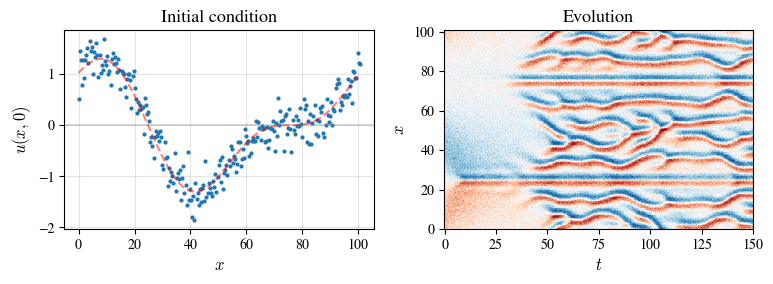

In [13]:
# IMPORT THE DATA
data_path = '../Datasets/KS.txt'
torch.manual_seed(0);

# Read in CSV data
U0 = torch.tensor(np.loadtxt(data_path, delimiter=','))
U = U0 if noise == 0 else add_noise(U0, noise)

# Reshape to Nx x ... x Nt tensor
[L, T] = [32*np.pi, 150]
[Nx, Nt] = [256, 301]
U = U.view(Nx, -1)
print(f"Imported tensor with shape: {U.numpy().shape}")

# Space and time
x = torch.linspace(0, L, Nx)
t = torch.linspace(0, T, Nt)

# Preview the data
X,T = torch.meshgrid(x, t, indexing='ij')
fig,ax = plt.subplots(1,2,figsize=(8,3))
ax[0].plot(x, U[:,0], '.', ms=4)
ax[0].plot(x, U0[:,0], '--', color='r', alpha=0.5)
ax[0].axhline(0, color='gray', alpha=0.3)
ax[0].set_title('Initial condition', fontsize=13)
ax[0].set_xlabel('$x$')
ax[0].set_ylabel('$u(x,0)$')
ax[0].grid(True, color="gray", alpha=0.2)
pcm = ax[1].pcolormesh(T, X, U, cmap='RdBu_r')
ax[1].set_title('Evolution', fontsize=13)
ax[1].set_xlabel('$t$')
ax[1].set_ylabel('$x$')
fig.tight_layout()
plt.show()

del fig,ax,X,L,T

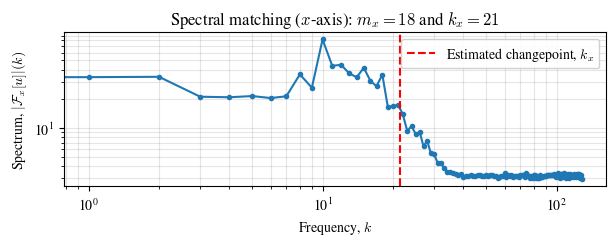

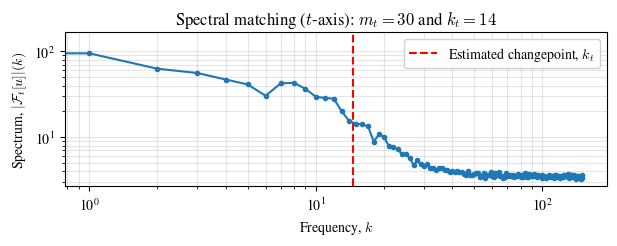

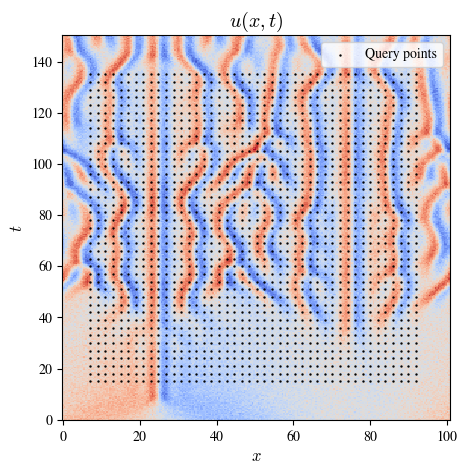

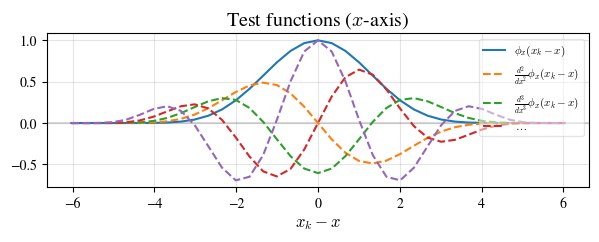

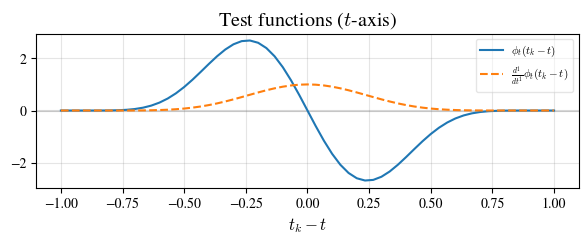

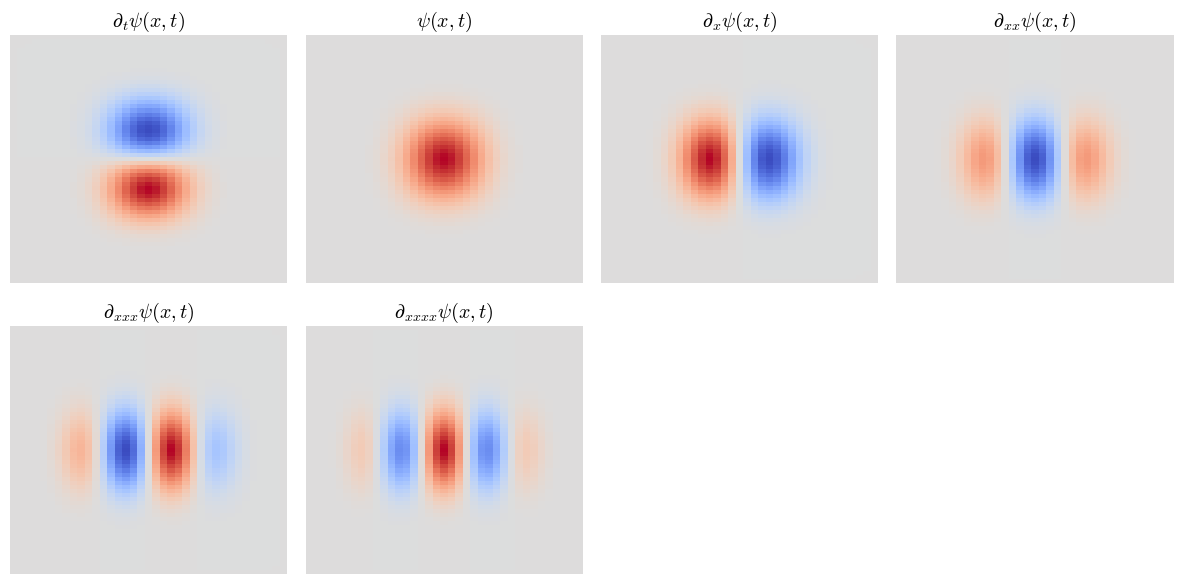

In [14]:
# Space-time grid
grid = [x,t]

# Derivative operators to include in library
derivatives = [[0,1], # d/dt
               [0,0], # identity
               [1,0], # d/dx
               [2,0], # d^2/dx^2
               [3,0], # d^3/dx^3
               [4,0]] # d^4/dx^4

# Candidate monomial terms to include in library
monomials = [[0], # constant
             [1], # u^1
             [2]] # u^2

model = WSINDy(U, derivatives, monomials, grid, equation_type='pde')

In [15]:
# Create standard library terms
[G,powers,derivs,rhs_names] = model.create_default_library()

# Display the library rendered in LaTex
lib_string = fr'\Theta({model.var_names[0]})=' + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

100%|██████████| 5/5 [00:00<00:00, 102.89it/s]


<IPython.core.display.Math object>

In [16]:
# Example of adding a funky non-homogeneous term: D_i cos(u)
i = 1
kernel = model.test_fcn_kernels[i]
scales_product = np.prod(model.x_scales + [model.t_scale])
cos_term = compute_weak_trig(U, kernel, model.spacing, freq=1., phase=0., scales_product=scales_product)

G.append(cos_term[model.conv_mask])
powers.append([0])
derivs.append(i)
rhs_names.append(r'\cos(u)' + model.derivative_names[i])

# Display the library rendered in LaTex
lib_string = fr'\Theta({model.var_names[0]})=' + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

del i, scales_product, kernel, cos_term

<IPython.core.display.Math object>

In [17]:
# Define WSINDy linear system
model.build_lhs()
model.set_library(G, powers, derivs, rhs_names)

# Find sparse weights
w = model.MSTLS()
model.print_report()

HYPER-PARAMETERS
test_fcn_support_radii = [18, 30]
test_fcn_poly_degrees = [11, 9]
subsample_rate = [5, 6]
[x_scales, t_scale] = [0.85, 0.07]
u_scale = 0.74
aux_scales = []

LIBRARY
Number of query points = 1804
Number of candidate terms = 12
cond(G) = 6.26e+01

RESULTS
PDE: u_{t} = - 0.49(u^2)_{x} - 0.99(u)_{xx} - 1.00(u)_{xxxx}
R^2 = 0.98
Nonzero terms = 3
Lambda = 1.33e-02
Loss = 0.26
Relative L2 error = 0.14


In [19]:
pde = symbolic_eqn(model.lhs_name, model.rhs_names, model.coeffs)
display(Math(pde))

<IPython.core.display.Math object>

In [10]:
# Reset variables for the next example
del model, U, G, powers, derivs, rhs_names, w, pde
del noise, x, t, grid, derivatives, monomials

### **SWIFT-HOHENBERG**

These data are taken from a numerical simulation of the $(2+1)$-dimensional Swift Hohenberg equation:

$$
\begin{align*}
u_t = (r-1)u + \delta{u}^2 - u^3
- \left(2u_{xx} + 2u_{yy}\right)
- \left(u_{xxxx} + 2u_{xxyy} + u_{yyyy}\right),
\quad \text{for} \quad
\begin{cases}
x \in [0, 30\pi],
\\
y \in [0, 30\pi],
\\
t \in [0, 20],
\end{cases}
\end{align*}
$$
with parameters $r = 0.4$ and $\delta = 1$.
- This example comes from MatLab's `Chebfun` package (see [this link](https://www.chebfun.org/examples/pde/SwiftHohenberg.html)).
- Since the [SH23.txt](../Datasets/SH23/SH23.txt) file (70.8 MB) is too big to store on GitHub, we provide [some MatLab code](../Datasets/SH23/SH23_simulation.m) that runs the simulation locally.

In [11]:
# Add observation noise?
noise = 0.1

Imported tensor with shape: (200, 200, 101)


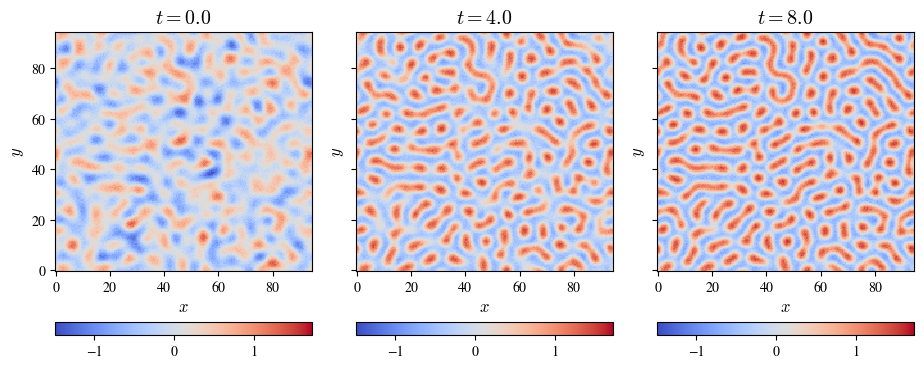

In [12]:
# IMPROT THE DATA
data_path = '../Datasets/SH23/SH23.txt'

# Read in CSV data
U = np.loadtxt(data_path, delimiter=',')
if noise == 0:
  U = torch.tensor(U)
else:
  U = torch.tensor(U)
  U = add_noise(U, noise)

# Reshape to Nx x ... x Nt tensor
[L, W, T] = [30*np.pi, 30*np.pi, 20]
[Nx, Ny, Nt] = [200, 200, 101]
U = U.view(Nx, Ny, -1)
print(f"Imported tensor with shape: {U.numpy().shape}")

# Space and time
x = torch.linspace(0, L, Nx)
y = torch.linspace(0, W, Ny)
t = torch.linspace(0, T, Nt)

# Plot the data
skip = 20
X,Y = np.meshgrid(x.numpy(), y.numpy())

fig,ax = plt.subplots(1,3, sharex=True, sharey=True, figsize=(9.4,4))
for j in range(3):
  Unp = U[:,:,skip*j].numpy()
  im = ax[j].pcolormesh(X, Y, Unp, cmap='coolwarm', vmin=U.min(), vmax=U.max())
  plt.colorbar(im, orientation='horizontal')
  ax[j].set_xlabel('$x$')
  ax[j].set_ylabel('$y$')
  ax[j].set_title(f'$t = {t[skip*j]}$')

fig.tight_layout()
plt.show()

del X,Y,L,W,T,Nx,Ny,Nt
del skip,j,Unp,fig,ax,im

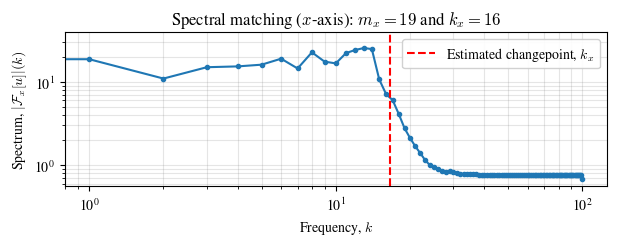

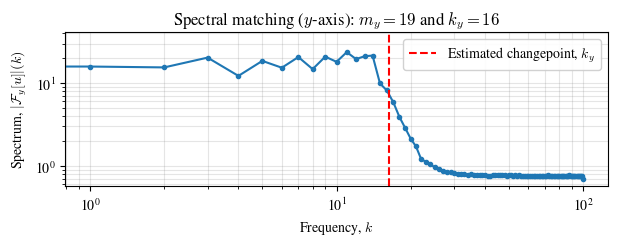

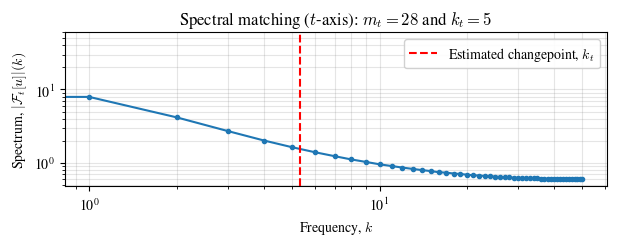

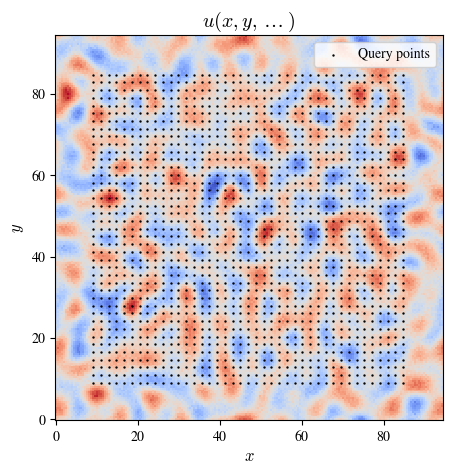

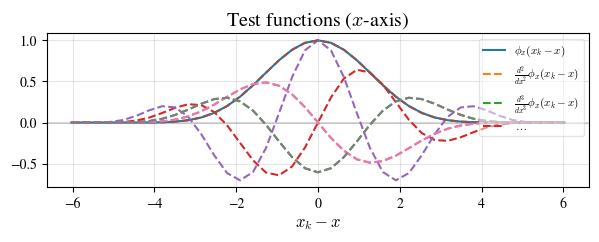

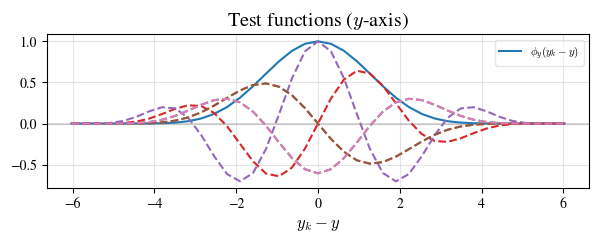

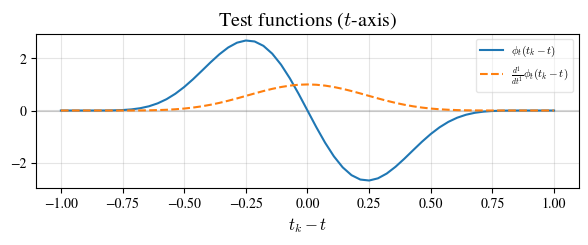

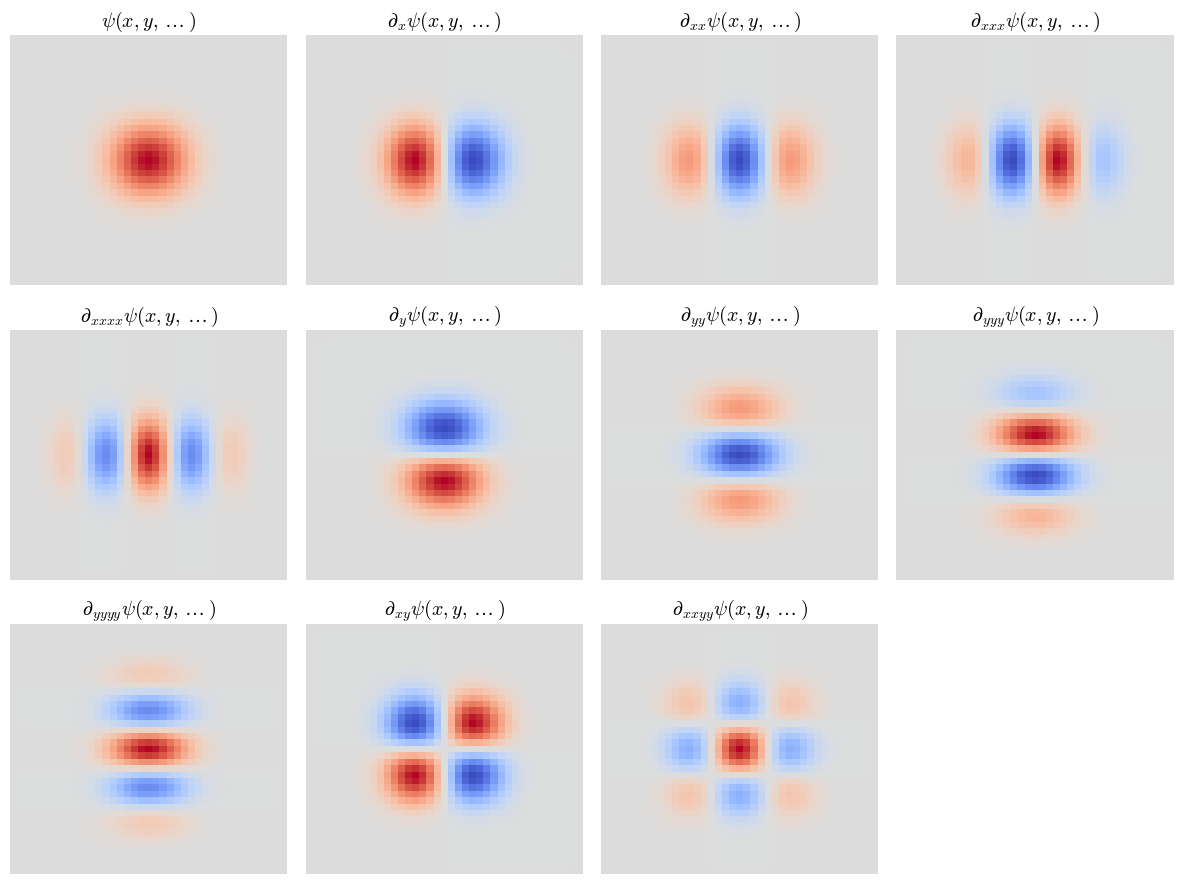

In [13]:
# Space-time grid
grid = [x,y,t]

# Derivative operators to include in library
derivatives = [[0,0,1], # d/dt
               [0,0,0], # identity
               [1,0,0], # d/dx
               [2,0,0], # d^2/dx^2
               [3,0,0], # d^3/dx^3
               [4,0,0], # d^4/dx^4
               [0,1,0], # d/dy
               [0,2,0], # d^2/dy^2
               [0,3,0], # d^3/dy^3
               [0,4,0], # d^4/dy^4
               [1,1,0], # d^2/dxdy
               [2,2,0]] # d^4/dx^2dy^2

# Candidate monomial terms to include in library
monomials = [[0], # constant
             [1], # u^1
             [2], # u^2
             [3]] # u^3

model = WSINDy(U, derivatives, monomials, grid, equation_type='pde')

In [14]:
# Create standard library terms
[G,powers,derivs,rhs_names] = model.create_default_library()

# Display the library rendered in LaTex
lib_string = fr'\Theta({model.var_names[0]})=' + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

100%|██████████| 11/11 [00:06<00:00,  1.65it/s]


<IPython.core.display.Math object>

In [15]:
# Let's manually remove some of the crazy high-order terms
remove_cols = [6,8,9,11,12,14,15] + [18,20,21,23,24,26,27] + [30,32,33]

for column in sorted(remove_cols, reverse=True):
  G.pop(column)
  powers.pop(column)
  derivs.pop(column)
  rhs_names.pop(column)

# Display the library rendered in LaTex
lib_string = fr'\Theta({model.var_names[0]})=' + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

del remove_cols, column

<IPython.core.display.Math object>

In [16]:
# Define WSINDy linear system
model.build_lhs()
model.set_library(G, powers, derivs, rhs_names)

# Find sparse weights
w = model.MSTLS()
model.print_report()
pde = symbolic_eqn(model.lhs_name, model.rhs_names, model.coeffs)
display(Math(pde))

HYPER-PARAMETERS
test_fcn_support_radii = [19, 19, 28]
test_fcn_poly_degrees = [11, 11, 9]
subsample_rate = [4, 4, 2]
[x_scales, t_scale] = [0.67, 0.67, 0.18]
u_scale = 0.96
aux_scales = []

LIBRARY
Number of query points = 38663
Number of candidate terms = 17
cond(G) = 2.95e+02

RESULTS
PDE: u_{t} = - 0.57(u) + 0.96(u^2) - 0.97(u^3) - 1.94(u)_{xx} - 0.97(u)_{xxxx} - 1.95(u)_{yy} - 0.98(u)_{yyyy} - 1.94(u)_{xxyy}
R^2 = 0.98
Nonzero terms = 8
Lambda = 1.60e-02
Loss = 0.51
Relative L2 error = 0.14


<IPython.core.display.Math object>

In [17]:
# Reset variables for the next example
del model, U, G, powers, derivs, rhs_names, w, pde
del noise, x, y, t, grid, derivatives, monomials

### **MHD EQUATIONS**

These data come from [this Johns Hopkins Turbulence Database numerical simulation](https://turbulence.idies.jhu.edu/datasets/homogeneousTurbulence/mhd) of forced turbulence in the incompressible MHD equations in $(3+1)$-dimensions:
$$
\begin{align*}
  \begin{cases}
    \boldsymbol{u}_t + (\boldsymbol{u} \cdot \nabla)\boldsymbol{u} =
    - \nabla p + \boldsymbol{j} \times \mathbf{B}
    + \nu\Delta\boldsymbol{u} + \mathbf{F},
    \\
    \mathbf{B}_t = \nabla \times (\boldsymbol{u} \times \mathbf{B}) + \eta\Delta\mathbf{B},
  \end{cases}
  \quad \text{where} \quad
  \begin{cases}
  \nabla \cdot \boldsymbol{u} = 0,
  \\
  \nabla \cdot \mathbf{B} = 0,
  \end{cases}
\end{align*}
$$
with parameters $\nu, \eta = 0.00011$.

Note that, explicitly,
$$\begin{align*}
\nabla \times (\boldsymbol{u} \times \mathbf{B}) &=
\begin{bmatrix}
(B_2u_1)_y-(B_1u_2)_y - (B_1u_3)_z + (B_3u_1)_z
\\
(B_3u_2)_z-(B_2u_3)_z - (B_2u_1)_x + (B_1u_2)_x
\\
(B_1u_3)_x-(B_3u_1)_x - (B_3u_2)_y + (B_2u_3)_y
\end{bmatrix}.
\end{align*}
$$

Here, we have defined the following quantities:
$$
\begin{align*}
  \begin{cases}
    \text{forcing,} \quad
    \mathbf{F} := \frac{1}{4}
    \big[\sin(2x)\cos(2y)\cos(2z) \mathbf{e}_x -
    \cos(2x)\sin(2y)\cos(2z) \mathbf{e}_y\big],
    \\
    \text{current density,} \quad
    \boldsymbol{j} := \nabla \times \mathbf{B}.
  \end{cases}
\end{align*}
$$

**Downloading the data:**
- See these [local installation notebooks](../Datasets/MHD/DEMO_Getcutout_local.ipynb) based on the "DEMO notebooks" sourced from the JHTDB [giverny GitHub repo](https://github.com/sciserver/giverny/tree/main).
- Also see [JHTDB's original local download instructions](https://turbulence.idies.jhu.edu/database/local/python).
- **Word of caution:** be careful not to rename downloaded `h5` files (these use keys associated with the file names) or else there will be no end to the suffering.

In [18]:
# This example requires the "h5py" package
import h5py

In [19]:
# Add observation noise?
noise = 0.2

In [20]:
# IMPORT THE MHD DATASET
file_path = '../Datasets/MHD/giverny_output/'
data_path_u = file_path + 'mhd1024_velocity.h5' # Velocity
data_path_b = file_path + 'mhd1024_magneticfield.h5' # Magnetic field

# Import h5 files
u_ = h5py.File(data_path_u, 'r')
b_ = h5py.File(data_path_b, 'r')

# Get spatial coordinates
[x, y, z] = (torch.tensor(np.array(u_[key_])) for key_ in ['xcoor', 'ycoor', 'zcoor'])

# Time axis
T = 2.5
Nt = 26
t = torch.linspace(0, T, Nt)

# Convert to torch tensors (and change Z,Y,X --> X,Y,Z ordering)
def tensorize(field, index):
  result = torch.stack([torch.as_tensor(np.array(elem))[..., index] for elem in field], dim=-1)
  return result.transpose(0,2)

# Keep only the snapshots (the files also contain 'xcoor', 'ycoor', 'zcoor', and 'values' keys)
u_ = [u_[key_] for key_ in u_.keys() if key_.startswith('velocity')]
b_ = [b_[key_] for key_ in b_.keys() if key_.startswith('magneticfield')]

U1 = add_noise(tensorize(u_,0), noise) # x-component
U2 = add_noise(tensorize(u_,1), noise) # y-component
U3 = add_noise(tensorize(u_,2), noise) # z-component

B1 = add_noise(tensorize(b_,0), noise) # x-component
B2 = add_noise(tensorize(b_,1), noise) # y-component
B3 = add_noise(tensorize(b_,2), noise) # z-component

print(f"Imported tensor(s) with shape: {U1.numpy().shape}")

# Coarsen the data?
COARSEN = 2

if COARSEN > 1:
  [U1, U2, U3, B1, B2, B3] = (V[0:-1:COARSEN, 0:-1:COARSEN, 0:-1:COARSEN, :] \
    for V in [U1, U2, U3, B1, B2, B3])
  [x, y, z] = (X[0:-1:COARSEN] for X in [x, y, z])
  print(f'Coarsened dimensions: {U1.numpy().shape}')

del data_path_u, data_path_b, u_, b_, T, Nt, COARSEN

FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = '../Datasets/MHD/giverny_output/mhd1024_velocity.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

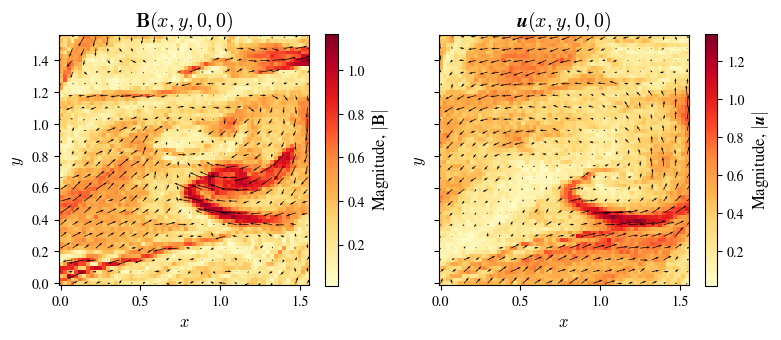

In [ ]:
# Plot the vector fields
X,Y = torch.meshgrid(x, y, indexing='ij')
fig, axes = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(8,4))

fields = [[B1, B2, B3], [U1, U2, U3]]
titles = [r"$\mathbf{B}(x,y,0,0)$", r"$\boldsymbol{u}(x,y,0,0)$"]
colorbar_labels = [r"Magnitude, $|\mathbf{B}|$", r"Magnitude, $|\boldsymbol{u}|$"]
skip = 3 # plot every n-th arrow

for i in range(2):
  ax = axes[i]
  [V1, V2, V3] = [V[:,:,0,0] for V in fields[i]]
  pcm = ax.pcolormesh(X, Y, torch.sqrt(V1**2 + V2**2 + V3**2), cmap='YlOrRd')
  ax.quiver(X[::skip,::skip], Y[::skip,::skip], V1[::skip,::skip], V2[::skip,::skip], color='k')
  fig.colorbar(pcm, ax=ax, label=colorbar_labels[i], shrink=0.7)
  ax.set_xlabel('$x$')
  ax.set_ylabel('$y$')
  ax.set_title(titles[i])
  ax.set_aspect('equal')

plt.tight_layout()
plt.show()

del X, Y, fig, ax, axes, pcm
del fields, titles, skip, V1, V2, V3

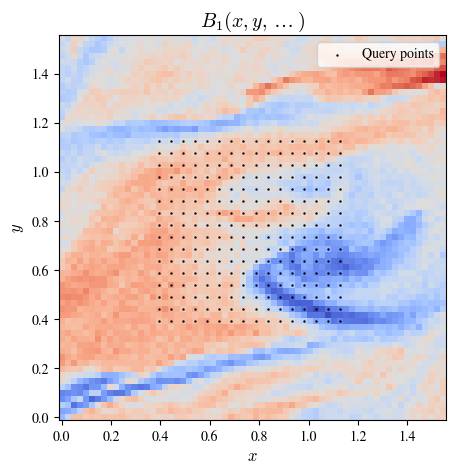

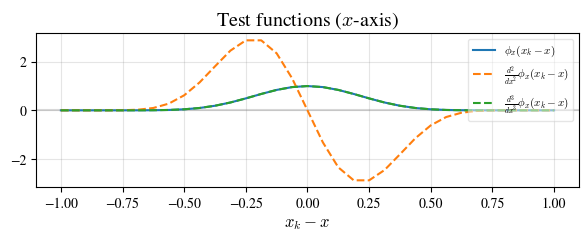

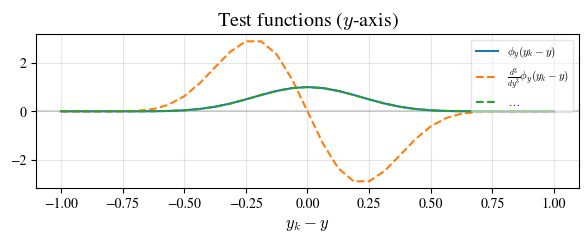

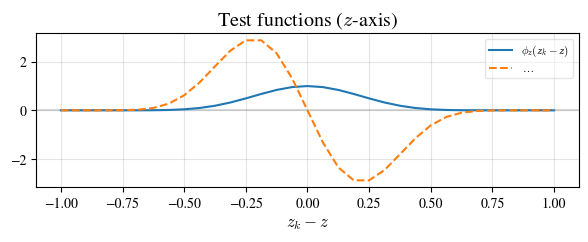

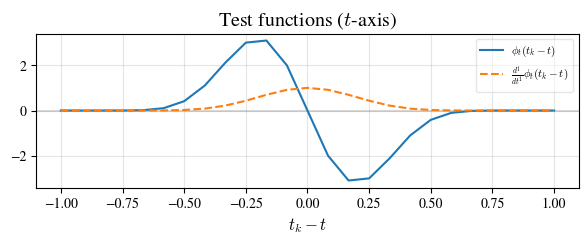

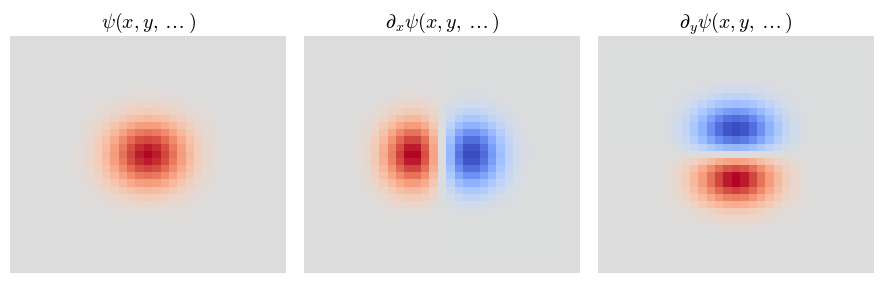

In [ ]:
# Space-time grid
grid = [x,y,z,t]

# Derivative operators to include in library
derivatives = [[0,0,0,1], # d/dt
               [0,0,0,0], # identity
               [1,0,0,0], # d/dx
               [0,1,0,0], # d/dy
               [0,0,1,0]] # d/dz

# Candidate monomial terms to include in library
monomials = [[0,0,0, 0,0,0], # constant
             [1,0,0, 0,0,0], # B_1
             [0,1,0, 0,0,0], # B_2
             [0,0,1, 0,0,0], # B_3
             # B_1 * u_n monomial combos
             [1,0,0, 1,0,0], # B_1 * u_1
             [1,0,0, 0,1,0], # B_1 * u_2
             [1,0,0, 0,0,1], # B_1 * u_3
             # B_2 * u_n monomial combos
             [0,1,0, 1,0,0], # B_2 * u_1
             [0,1,0, 0,1,0], # B_2 * u_2
             [0,1,0, 0,0,1], # B_2 * u_3
             # B_3 * u_n monomial combos
             [0,0,1, 1,0,0], # B_3 * u_1
             [0,0,1, 0,1,0], # B_3 * u_2
             [0,0,1, 0,0,1]] # B_3 * u_3

# Create models for each component of the magnetic field
aux_vars = [[B2,B3,U1,U2,U3], # for the B_1 model
            [B1,B3,U1,U2,U3], # for the B_2 model
            [B1,B2,U1,U2,U3]] # for the B_3 model

var_names = [[r'{B_1}','B_2','B_3','u_1','u_2','u_3'],
             [r'{B_2}','B_1','B_3','u_1','u_2','u_3'],
             [r'{B_3}','B_1','B_2','u_1','u_2','u_3']]

params = {
    'equation_type': 'pde',
    'test_fcn_support_radii': [16, 16, 16, 12],
    'subsample_rate': [2, 2, 2, 1]
}

B1_model = WSINDy(B1, derivatives, monomials, grid, **params,
                  aux_vars=aux_vars[0], var_names=var_names[0], verbosity=True)
B2_model = WSINDy(B2, derivatives, monomials, grid, **params,
                  aux_vars=aux_vars[1], var_names=var_names[1], verbosity=False)
B3_model = WSINDy(B3, derivatives, monomials, grid, **params,
                  aux_vars=aux_vars[2], var_names=var_names[2], verbosity=False)
                  

In [ ]:
# Find the governing PDEs
pdes = []
for i,model in enumerate([B1_model, B2_model, B3_model]):
    # Only build the library once
    if i == 0:
        [G,powers,derivs,rhs_names] = model.create_default_library()
        lib_string = fr'\Theta(B_1,B_2,B_3,u_1,u_2,u_3)=' + r'[' + r', \, '.join(rhs_names) + r']'
        display(Math(lib_string))

    # Define the WSINDy linear system
    model.build_lhs()
    model.set_library(G, powers, derivs, rhs_names)

    # Find sparse weights
    _ = model.MSTLS()

    # Only print one report
    if i == 0:
        model.print_report()
        
    pde = symbolic_eqn(model.lhs_name, model.rhs_names, model.coeffs)
    pdes.append(pde)

100%|██████████| 4/4 [00:27<00:00,  6.94s/it]


<IPython.core.display.Math object>

HYPER-PARAMETERS
test_fcn_support_radii = [16, 16, 16, 12]
test_fcn_poly_degrees = [11, 11, 11, 13]
subsample_rate = [2, 2, 2, 1]
[x_scales, t_scale] = [2.55, 2.55, 2.55, 0.83]
u_scale = 1.00
aux_scales = [1.0, 1.0, 1.0, 1.0, 1.0]

LIBRARY
Number of query points = 8192
Number of candidate terms = 49
cond(G) = 7.79e+02

RESULTS
PDE: {B_1}_{t} = - 1.00({B_1} u_2)_{y} + 0.99(B_2 u_1)_{y} - 1.01({B_1} u_3)_{z} + 0.99(B_3 u_1)_{z}
R^2 = 1.00
Nonzero terms = 4
Lambda = 1.10e-02
Loss = 0.10
Relative L2 error = 0.03


In [ ]:
# Print all the PDEs in the system
for pde in pdes:
    display(Math(pde))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Recall that
$$
\begin{align*}
\nabla \times (\boldsymbol{u} \times \mathbf{B}) &=
\begin{bmatrix}
(B_2u_1)_y-(B_1u_2)_y - (B_1u_3)_z + (B_3u_1)_z
\\
(B_3u_2)_z-(B_2u_3)_z - (B_2u_1)_x + (B_1u_2)_x
\\
(B_1u_3)_x-(B_3u_1)_x - (B_3u_2)_y + (B_2u_3)_y
\end{bmatrix}.
\end{align*}
$$

In [ ]:
# Reset variables for the next example
del B1_model, B2_model, B3_model, G, powers, derivs, rhs_names
del B1, B2, B3, U1, U2, U3
del noise, x, y, t, grid, derivatives, monomials, pde

## **ODE EXAMPLES**

### **LOGISTIC EQUATION**

In this example, we use data representing a corrupted numerical solution of the Logistic equation:
$$
\begin{align*}
  \dot u = r u\left(1 - \frac{u}{\kappa}\right),
  \quad \text{with} \quad
  \begin{cases}
    r = 1.5,
    \\
    \kappa=2.
  \end{cases}
\end{align*}
$$

In [21]:
# Add observation noise?
noise = 0.2

Imported tensor with shape: (501,)


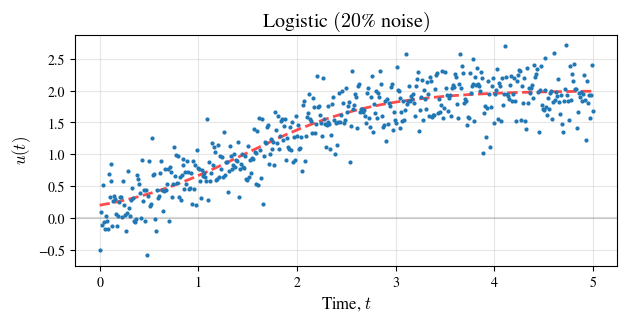

In [22]:
# IMPORT THE DATA
data_path = '../Datasets/logistic.txt'
torch.manual_seed(0);

# Read in CSV data
U0 = torch.tensor(np.loadtxt(data_path, delimiter=','))
U = U0 if noise == 0 else add_noise(U0, noise)
print(f"Imported tensor with shape: {U.numpy().shape}")

# Time
[T, Nt] = [5, 501]
t = torch.linspace(0, T, Nt)

# Preview the data
plt.figure(figsize=(7,3))
plt.axhline(0, color='gray', alpha=0.3)
plt.plot(t, U0, '--', color='r', lw=2, alpha=0.7)
plt.plot(t, U, '.', ms=4)
plt.xlabel('Time, $t$')
plt.ylabel('$u(t)$')
plt.title(f'Logistic $({noise*100:.0f}$% noise$)$')
plt.grid(True, alpha=0.3)
plt.show()

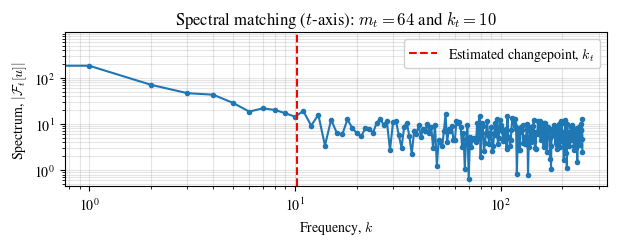

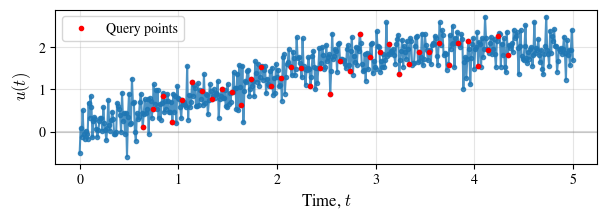

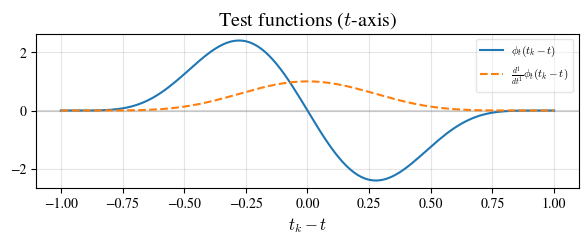

In [23]:
# Temporal grid
grid = [t]

# Derivative operators to include in library
derivatives = [[1], # d/dt
               [0]] # identity

# Candidate monomial terms to include in library
monomials = [[0], # constant
             [1], # u^1
             [2]] # u^2

model = WSINDy(U, derivatives, monomials, grid, equation_type='ode')

In [24]:
# Create standard library terms
[G,powers,derivs,rhs_names] = model.create_default_library()

# Display the library rendered in LaTex
lib_string = fr'\Theta({model.var_names[0]})=' + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

# Define the WSINDy linear system
model.build_lhs()
model.set_library(G, powers, derivs, rhs_names)

# Find sparse weights
w = model.MSTLS()
model.print_report()

# Print out the symbolic equation
pde = symbolic_eqn(model.lhs_name, model.rhs_names, model.coeffs)
display(Math(pde))

100%|██████████| 1/1 [00:00<00:00, 1048.05it/s]


<IPython.core.display.Math object>

HYPER-PARAMETERS
test_fcn_support_radii = [64]
test_fcn_poly_degrees = [7]
subsample_rate = [10]
t_scale = 1.56
u_scale = 0.73
aux_scales = []

LIBRARY
Number of query points = 38
Number of candidate terms = 3
cond(G) = 5.33e+01

RESULTS
ODE: \dot{u} = + 1.50(u) - 0.73(u^2)
R^2 = 0.69
Nonzero terms = 2
Lambda = 8.69e-02
Loss = 0.71
Relative L2 error = 0.33


<IPython.core.display.Math object>

### **LOTKA-VOLTERRA**

Now, here's an example with a 2-dimensional nonlinear ODE:
$$
\begin{align*}
  \begin{cases}
    \dot{x} = +ax - xy,\\
    \dot{y} = -by + xy,
  \end{cases}
  \quad \text{with} \quad
  \begin{cases}
    a = 1.5,
    \\
    b = 3.
  \end{cases}
\end{align*}
$$

In [25]:
# Add observation noise?
noise = 0.1

Imported tensors with shape: (1001,)


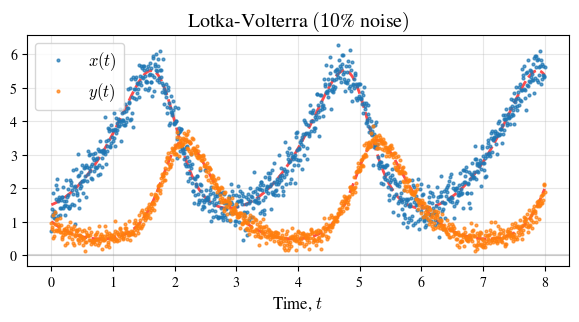

In [26]:
# IMPORT THE DATA
data_path = '../Datasets/lotka_volterra.txt'
torch.manual_seed(0);

# Read in CSV data
[X0, Y0] = torch.tensor(np.loadtxt(data_path, delimiter=','))
X = X0 if noise == 0 else add_noise(X0, noise)
Y = Y0 if noise == 0 else add_noise(Y0, noise)
print(f"Imported tensors with shape: {X.numpy().shape}")

# Time
[T, Nt] = [8, 1001]
t = torch.linspace(0, T, Nt)

# Preview the data
plt.figure(figsize=(7,3))
plt.axhline(0, color='gray', alpha=0.3)
plt.plot(t, X0, '--', color='r', lw=2, alpha=0.7)
plt.plot(t, Y0, '--', color='r', lw=2, alpha=0.7)
plt.plot(t, X, '.', ms=4, label='$x(t)$', alpha=0.7)
plt.plot(t, Y, '.', ms=4, label='$y(t)$', alpha=0.7)
plt.xlabel('Time, $t$')
plt.title(f'Lotka-Volterra $({noise*100:.0f}$% noise$)$')
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left')
plt.show()

In [27]:
# Temporal grid
grid = [t]

# Derivative operators to include in library
derivatives = [[1], # d/dt
               [0]] # identity

# Candidate monomial terms to include in library
monomials = [[0,0], # constant
             [1,0], # x^1
             [2,0], # x^2
             [1,1], # x^1 * y^1
             [0,1], # y^1
             [0,2]] # y^2

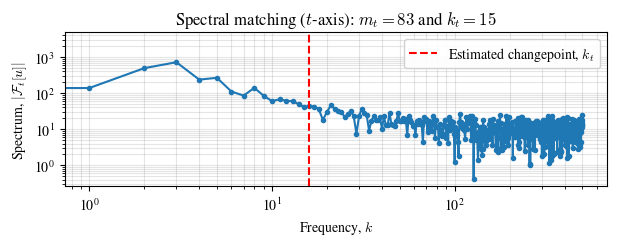

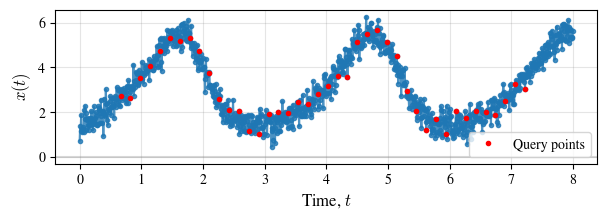

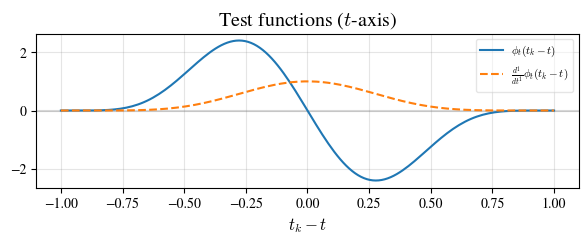

100%|██████████| 1/1 [00:00<00:00, 566.34it/s]


<IPython.core.display.Math object>

HYPER-PARAMETERS
test_fcn_support_radii = [83]
test_fcn_poly_degrees = [7]
subsample_rate = [20]
t_scale = 1.51
u_scale = 0.47
aux_scales = [0.61]

LIBRARY
Number of query points = 42
Number of candidate terms = 6
cond(G) = 2.69e+02

RESULTS
ODE: \dot{x} = + 1.49(x) - 0.99(x y)
R^2 = 1.00
Nonzero terms = 2
Lambda = 8.69e-02
Loss = 0.35
Relative L2 error = 0.05


<IPython.core.display.Math object>

In [28]:
# MODEL FOR THE X VARIABLE
params = {
    'equation_type': 'ode',
    'aux_vars': [Y],
    'var_names': ['x','y']
}
x_model = WSINDy(X, derivatives, monomials, grid, **params)

# Create standard library terms
[G,powers,derivs,rhs_names] = x_model.create_default_library()
lib_string = fr'\Theta({x_model.var_names[0]},{x_model.var_names[1]})='\
    + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

# Define the WSINDy linear system
x_model.build_lhs()
x_model.set_library(G, powers, derivs, rhs_names)

# Find sparse weights
_ = x_model.MSTLS()
x_model.print_report()

# Print out the symbolic equation
pde = symbolic_eqn(x_model.lhs_name, x_model.rhs_names, x_model.coeffs)
display(Math(pde))

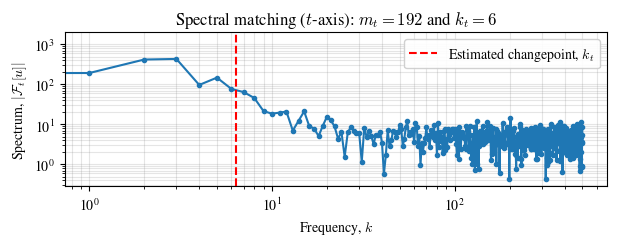

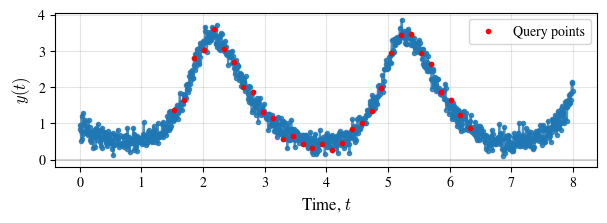

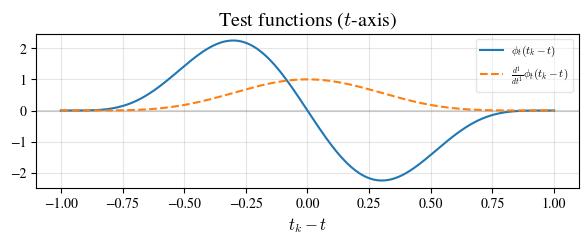

100%|██████████| 1/1 [00:00<00:00, 611.41it/s]


<IPython.core.display.Math object>

HYPER-PARAMETERS
test_fcn_support_radii = [192]
test_fcn_poly_degrees = [6]
subsample_rate = [20]
t_scale = 0.65
u_scale = 0.61
aux_scales = [0.47]

LIBRARY
Number of query points = 31
Number of candidate terms = 6
cond(G) = 2.60e+03

RESULTS
ODE: \dot{y} = - 3.03(y) + 1.00(y x)
R^2 = 1.00
Nonzero terms = 2
Lambda = 1.53e-01
Loss = 0.35
Relative L2 error = 0.04


<IPython.core.display.Math object>

In [29]:
# MODEL FOR THE Y VARIABLE
params = {
    'equation_type': 'ode',
    'aux_vars': [X],
    'var_names': ['y','x']
}
y_model = WSINDy(Y, derivatives, monomials, grid, **params)

# Create standard library terms
[G,powers,derivs,rhs_names] = y_model.create_default_library()
lib_string = fr'\Theta({y_model.var_names[0]},{y_model.var_names[1]})='\
    + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

# Define the WSINDy linear system
y_model.build_lhs()
y_model.set_library(G, powers, derivs, rhs_names)

# Find sparse weights
_ = y_model.MSTLS()
y_model.print_report()

# Print out the symbolic equation
pde = symbolic_eqn(y_model.lhs_name, y_model.rhs_names, y_model.coeffs)
display(Math(pde))

### **LORENZ '63**

This example uses data sourced from the all-time classic example of chaotic dynamics -- the Lorenz '63 system:
$$
\begin{align*}
  \begin{cases}
    \dot{x} = \sigma(y-x),\\
    \dot{y} = x(\rho-z)-y,\\
    \dot{z} = xy-\beta z,
  \end{cases}
  \quad \text{with} \quad
  \begin{cases}
    \sigma = 10,
    \\
    \rho = 28,
    \\
    \beta = 8/3.
  \end{cases}
\end{align*}
$$

In [30]:
# Add observation noise?
noise = 0.05

Imported tensors with shape: (1501,)


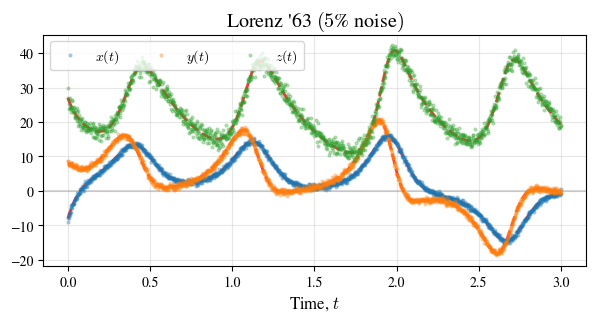

In [31]:
# IMPORT THE DATA
data_path = '../Datasets/lorenz.txt'
torch.manual_seed(0);

# Read in CSV data
[X0, Y0, Z0] = torch.tensor(np.loadtxt(data_path, delimiter=','))
X = X0 if noise == 0 else add_noise(X0, noise)
Y = Y0 if noise == 0 else add_noise(Y0, noise)
Z = Z0 if noise == 0 else add_noise(Z0, noise)
print(f"Imported tensors with shape: {X.numpy().shape}")

# Time
[T, Nt] = [3, 1501]
t = torch.linspace(0, T, Nt)

# Preview the data
plt.figure(figsize=(7,3))
plt.axhline(0, color='gray', alpha=0.3)
plt.plot(t, X0, '--', color='r', lw=2, alpha=0.8)
plt.plot(t, Y0, '--', color='r', lw=2, alpha=0.8)
plt.plot(t, Z0, '--', color='r', lw=2, alpha=0.8)
plt.plot(t, X, '.', ms=4, label='$x(t)$', alpha=0.3)
plt.plot(t, Y, '.', ms=4, label='$y(t)$', alpha=0.3)
plt.plot(t, Z, '.', ms=4, label='$z(t)$', alpha=0.3)
plt.xlabel('Time, $t$')
plt.title(f"Lorenz '63 $({noise*100:.0f}$% noise$)$")
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left', ncol=3, fontsize=10)
plt.show()

In [32]:
# Temporal grid
grid = [t]

# Derivative operators to include in library
derivatives = [[1], # d/dt
               [0]] # identity

# Candidate monomial terms to include in library
monomials = [[0,0,0], # constant
             [1,0,0], # x^1
             [0,1,0], # y^1
             [0,0,1], # z^1
             [2,0,0], # x^2
             [1,1,0], # x^1 * y^1
             [1,0,1], # x^1 * z^1
             [0,2,0], # y^2
             [0,1,1], # y^1 * z^1
             [0,0,2]] # z^2

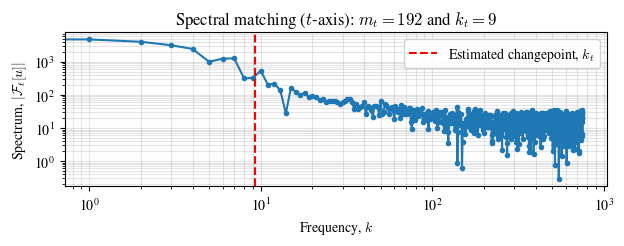

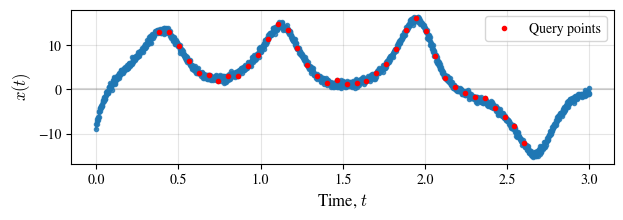

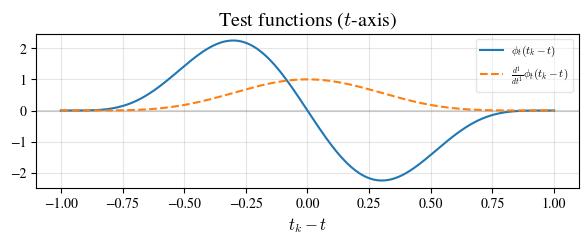

100%|██████████| 1/1 [00:00<00:00, 434.10it/s]


<IPython.core.display.Math object>

HYPER-PARAMETERS
test_fcn_support_radii = [192]
test_fcn_poly_degrees = [6]
subsample_rate = [30]
t_scale = 2.60
u_scale = 0.29
aux_scales = [0.26, 0.18]

LIBRARY
Number of query points = 38
Number of candidate terms = 10
cond(G) = 5.97e+03

RESULTS
ODE: \dot{x} = - 9.97(x) + 9.98(y)
R^2 = 1.00
Nonzero terms = 2
Lambda = 4.94e-02
Loss = 0.21
Relative L2 error = 0.01


<IPython.core.display.Math object>

In [33]:
# MODEL FOR THE X VARIABLE
params = {
    'equation_type': 'ode',
    'aux_vars': [Y,Z],
    'var_names': ['x','y','z']
}
x_model = WSINDy(X, derivatives, monomials, grid, **params)

# Create standard library terms
[G,powers,derivs,rhs_names] = x_model.create_default_library()
lib_string = \
    fr'\Theta({x_model.var_names[0]},{x_model.var_names[1]},{x_model.var_names[2]})='\
    + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

# Define the WSINDy linear system
x_model.build_lhs()
x_model.set_library(G, powers, derivs, rhs_names)

# Find sparse weights
_ = x_model.MSTLS()
x_model.print_report()

# Print out the symbolic equation
pde = symbolic_eqn(x_model.lhs_name, x_model.rhs_names, x_model.coeffs)
display(Math(pde))

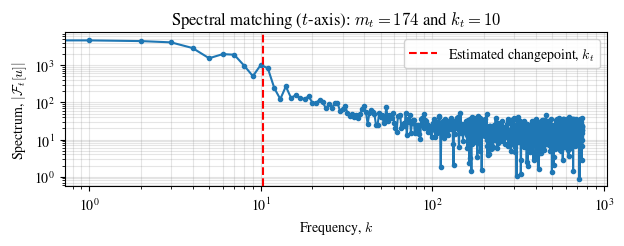

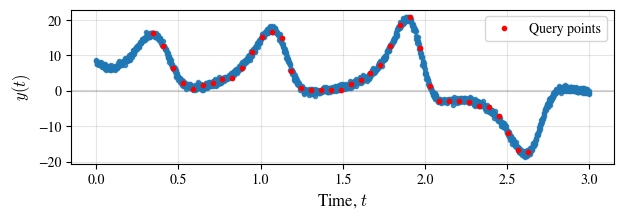

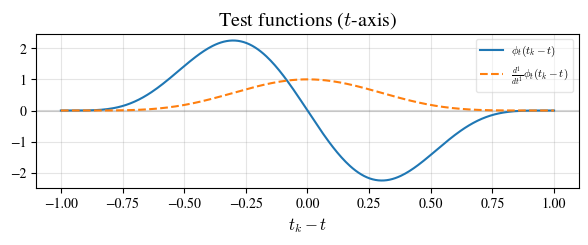

100%|██████████| 1/1 [00:00<00:00, 484.83it/s]


<IPython.core.display.Math object>

HYPER-PARAMETERS
test_fcn_support_radii = [174]
test_fcn_poly_degrees = [6]
subsample_rate = [30]
t_scale = 2.87
u_scale = 0.26
aux_scales = [0.29, 0.18]

LIBRARY
Number of query points = 39
Number of candidate terms = 10
cond(G) = 4.12e+03

RESULTS
ODE: \dot{y} = - 0.91(y) + 27.86(x) - 1.00(x z)
R^2 = 1.00
Nonzero terms = 3
Lambda = 5.96e-02
Loss = 0.31
Relative L2 error = 0.01


<IPython.core.display.Math object>

In [34]:
# MODEL FOR THE Y VARIABLE
params = {
    'equation_type': 'ode',
    'aux_vars': [X,Z],
    'var_names': ['y','x','z']
}
y_model = WSINDy(Y, derivatives, monomials, grid, **params)

# Create standard library terms
[G,powers,derivs,rhs_names] = y_model.create_default_library()
lib_string = \
    fr'\Theta({y_model.var_names[0]},{y_model.var_names[1]},{y_model.var_names[2]})='\
    + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

# Define the WSINDy linear system
y_model.build_lhs()
y_model.set_library(G, powers, derivs, rhs_names)

# Find sparse weights
_ = y_model.MSTLS()
y_model.print_report()

# Print out the symbolic equation
pde = symbolic_eqn(y_model.lhs_name, y_model.rhs_names, y_model.coeffs)
display(Math(pde))

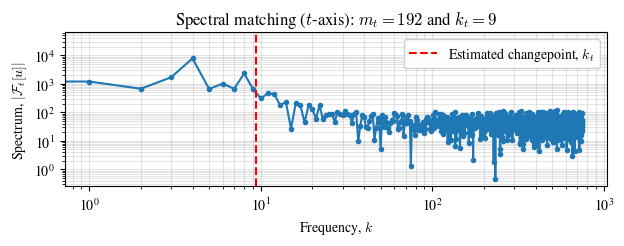

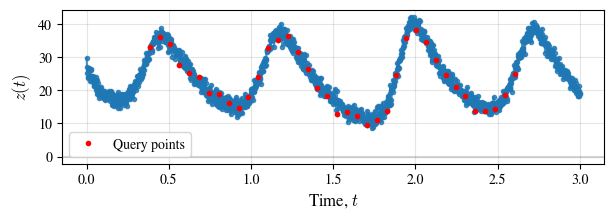

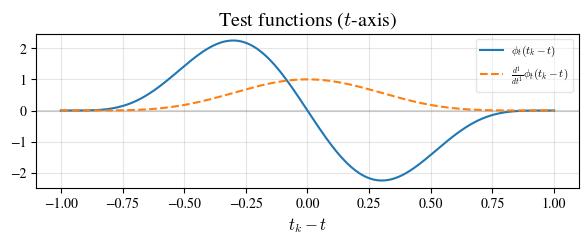

100%|██████████| 1/1 [00:00<00:00, 480.56it/s]


<IPython.core.display.Math object>

HYPER-PARAMETERS
test_fcn_support_radii = [192]
test_fcn_poly_degrees = [6]
subsample_rate = [30]
t_scale = 2.60
u_scale = 0.18
aux_scales = [0.29, 0.26]

LIBRARY
Number of query points = 38
Number of candidate terms = 10
cond(G) = 5.97e+03

RESULTS
ODE: \dot{z} = - 2.65(z) + 1.00(x y)
R^2 = 1.00
Nonzero terms = 2
Lambda = 7.20e-02
Loss = 0.21
Relative L2 error = 0.01


<IPython.core.display.Math object>

In [35]:
# MODEL FOR THE Z VARIABLE
params = {
    'equation_type': 'ode',
    'aux_vars': [X,Y],
    'var_names': ['z','x','y']
}
z_model = WSINDy(Z, derivatives, monomials, grid, **params)

# Create standard library terms
[G,powers,derivs,rhs_names] = z_model.create_default_library()
lib_string = \
    fr'\Theta({z_model.var_names[0]},{z_model.var_names[1]},{z_model.var_names[2]})='\
    + r'[' + r', \, '.join(rhs_names) + r']'
display(Math(lib_string))

# Define the WSINDy linear system
z_model.build_lhs()
z_model.set_library(G, powers, derivs, rhs_names)

# Find sparse weights
_ = z_model.MSTLS()
z_model.print_report()

# Print out the symbolic equation
pde = symbolic_eqn(z_model.lhs_name, z_model.rhs_names, z_model.coeffs)
display(Math(pde))

## **HYPERPARAMETER SWEEPS**

Automated hyperparameter sweeps over the main WSINDy parameters:
- MSTLS threshold values $\lambda$
- Scaling invariant preconditioning (on/off)
- Test function support radii $(m_x, \dots, m_t)$

Note that a CSV file can be saved by adding `csv_path='[output_file_name].csv'` to the `hyper_parameter_sweep(...)` call.

### **PDE EXAMPLE**

This example uses the Kuramoto Sivashinsky data at 20% noise.

In [36]:
# Import the data
U = torch.tensor(np.loadtxt('../Datasets/KS.txt', delimiter=','))
x = torch.linspace(0, 32*np.pi, 256)
t = torch.linspace(0, 150, 301)

# Add desired noise level
noise = 0.2
torch.manual_seed(0);
U = add_noise(U, noise).view(256, -1)

# Set up the WSINDy system
grid = [x,t]

# Derivative operators to include in library
derivatives = [[0,1], # d/dt
               [0,0], # identity
               [1,0], # d/dx
               [2,0], # d^2/dx^2
               [3,0], # d^3/dx^3
               [4,0]] # d^4/dx^4

# Candidate monomial terms to include in library
monomials = [[0], # constant
             [1], # u^1
             [2]] # u^2

model = WSINDy(U, derivatives, monomials, grid, verbosity=False, equation_type='pde')
[G,powers,derivs,rhs_names] = model.create_default_library()
model.build_lhs()
model.set_library(G, powers, derivs, rhs_names)
_ = model.MSTLS()

# Define the true model for reference
lhs_name = model.format_lhs_name()
true_coeffs = {'(u^2)_{x}': -0.5, '(u)_{xx}': -1.0, '(u)_{xxxx}': -1.0}
true_model = r'{u}_t = ' + ' '.join(str(true_coeffs[term])+term for term in true_coeffs)

100%|██████████| 41/41 [01:52<00:00,  2.75s/it]


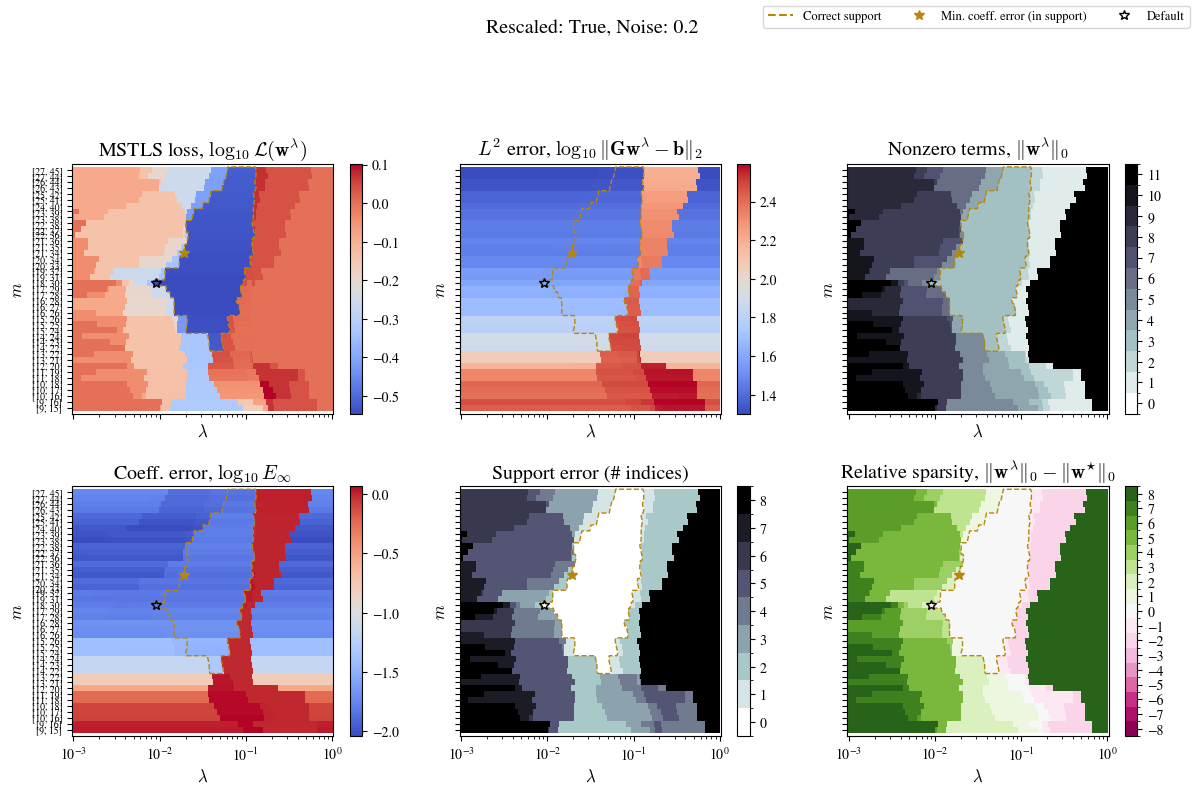

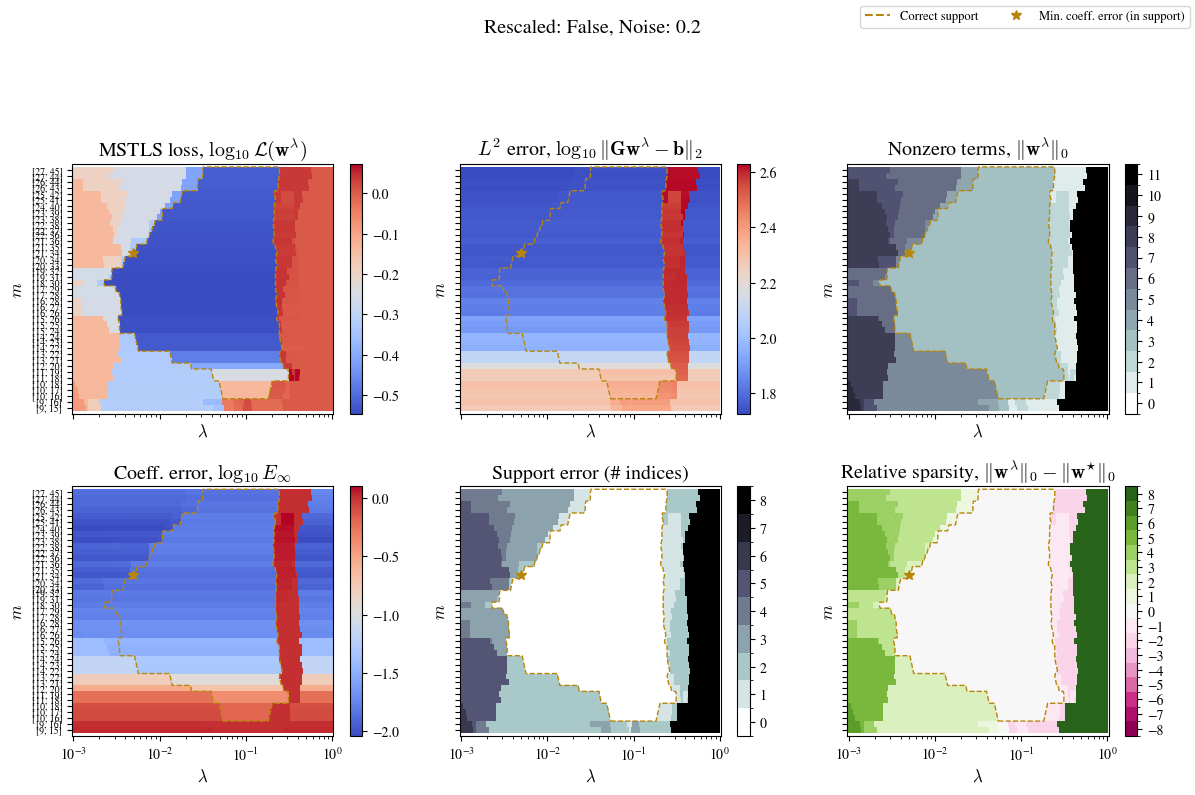

In [37]:
# Pick sweep parameters
sweep_params = {
    'lhs_name': lhs_name,
    'true_coeffs': true_coeffs,
    'noise': noise
}

# RUN THE SWEEP
results = model.hyperparameter_sweep(**sweep_params)

In [5]:
# Most common models across the sweep
from collections import Counter

for model_str,count in Counter(results['model']).most_common(4):
  print(f'{count:3d}/{len(results["model"])} fits: {model_str}')

1428/16400 fits: u_{t} = - 0.49(u^2)_{x} - 1.00(u)_{xx} - 1.00(u)_{xxxx}
1201/16400 fits: u_{t} = - 0.49(u^2)_{x} - 0.99(u)_{xx} - 0.99(u)_{xxxx}
991/16400 fits: u_{t} = - 0.49(u^2)_{x} - 0.99(u)_{xx} - 1.00(u)_{xxxx}
500/16400 fits: u_{t} = + 0.02(u)_{xxxx}


### **ODE EXAMPLE**

Here, we show an example using the $y$-component of the Lorenz '63 system.

In [6]:
# Import the data
data_path = '../Datasets/lorenz.txt'
[X0, Y0, Z0] = torch.tensor(np.loadtxt(data_path, delimiter=','))

[T, Nt] = [3, 1501]
t = torch.linspace(0, T, Nt)

# Set desired noise level
noise = 0.05
torch.manual_seed(0);

X = X0 if noise == 0 else add_noise(X0, noise)
Y = Y0 if noise == 0 else add_noise(Y0, noise)
Z = Z0 if noise == 0 else add_noise(Z0, noise)
print(f"Imported tensors with shape: {X.numpy().shape}")

# Set up the WSINDy system
grid = [t]

derivatives = [[1], # d/dt
               [0]] # identity
               
monomials = [[0,0,0], # constant
             [1,0,0], # x^1
             [0,1,0], # y^1
             [0,0,1], # z^1
             [2,0,0], # x^2
             [1,1,0], # x^1 * y^1
             [1,0,1], # x^1 * z^1
             [0,2,0], # y^2
             [0,1,1], # y^1 * z^1
             [0,0,2]] # z^2

params = {
    'equation_type': 'ode',
    'aux_vars': [X,Z],
    'var_names': ['y','x','z'],
    'verbosity': False
}

model = WSINDy(Y, derivatives, monomials, grid, **params)
[G,powers,derivs,rhs_names] = model.create_default_library()
model.build_lhs()
model.set_library(G, powers, derivs, rhs_names)
_ = model.MSTLS()

# Define the true model for reference
lhs_name = model.format_lhs_name()
true_coeffs = {'(x)': 28.0, '(y)': -1.0, '(x z)': -1.0}
true_model = r'\dot{y} = +' + ' '.join(str(true_coeffs[term])+term for term in true_coeffs)

Imported tensors with shape: (1501,)


100%|██████████| 61/61 [00:17<00:00,  3.57it/s]


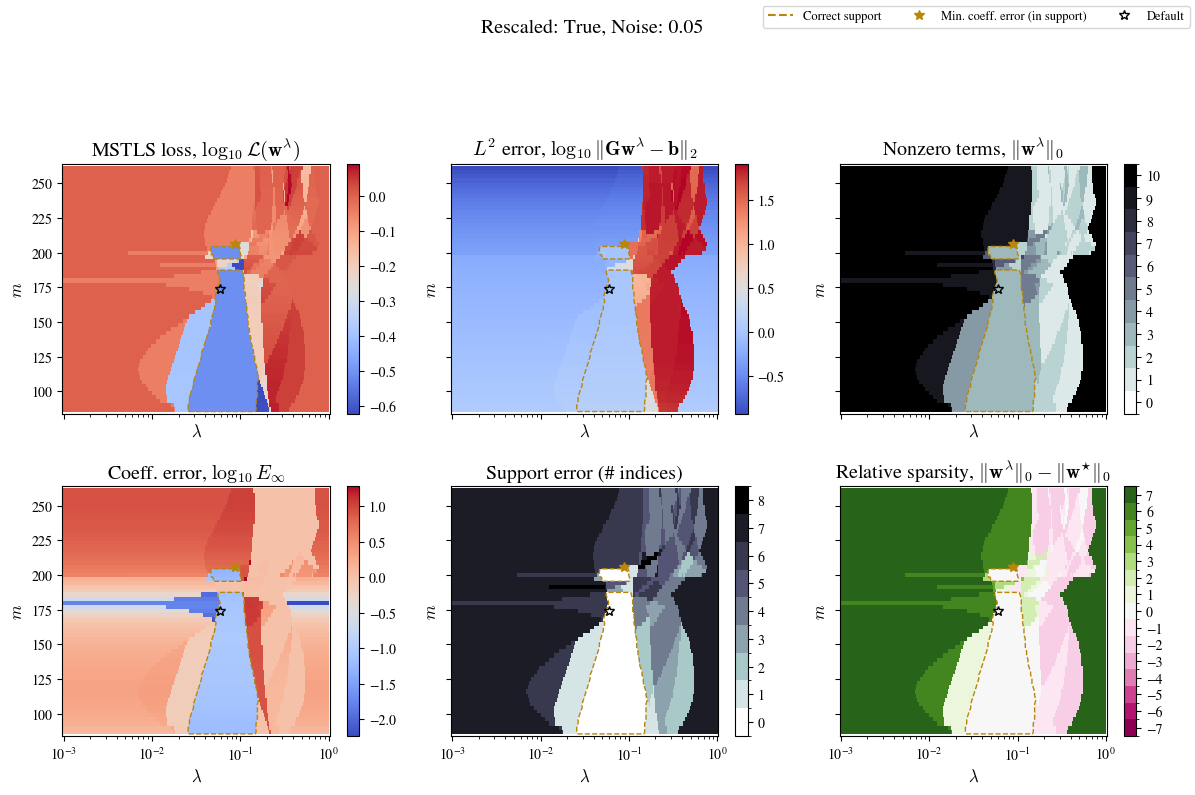

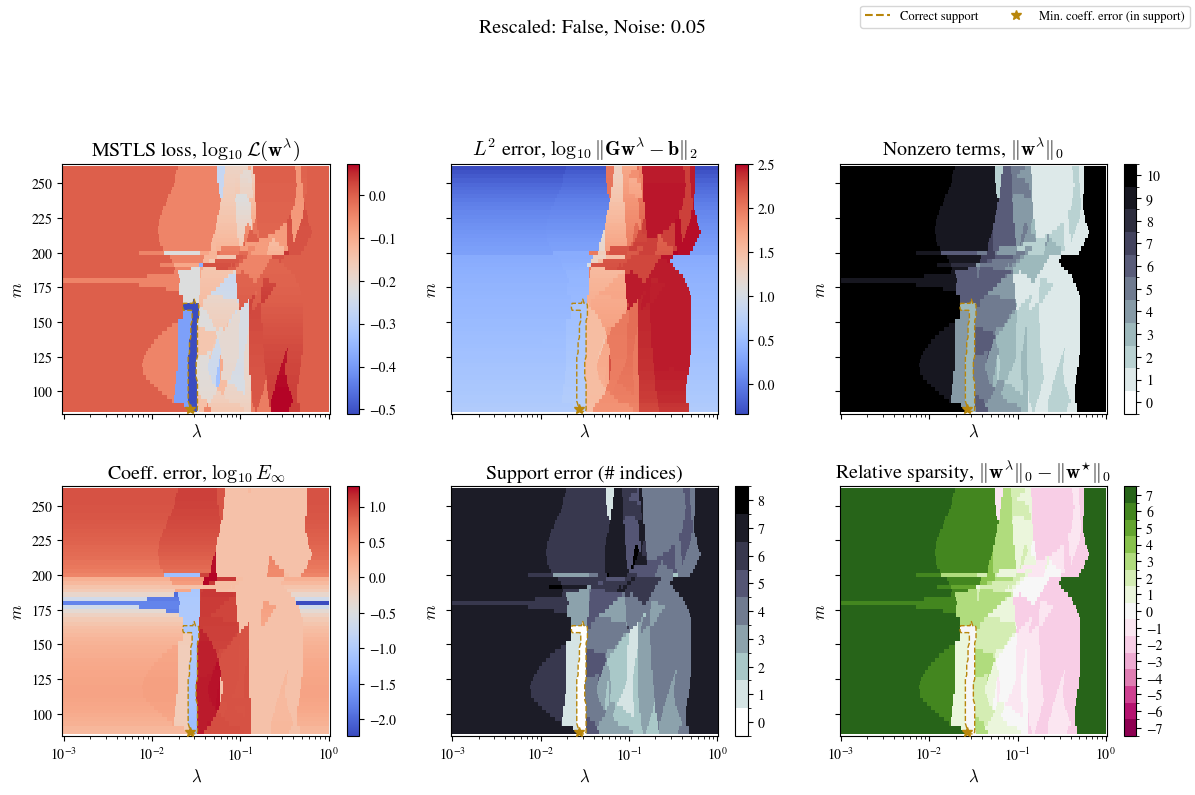

In [ ]:
# Pick sweep parameters
sweep_params = {
    'lhs_name': lhs_name,
    'true_coeffs': true_coeffs,
    'noise': noise
}

# RUN THE SWEEP
results = model.hyperparameter_sweep(**sweep_params)

In [10]:
# Most common models across the sweep
from collections import Counter

for model_str,count in Counter(results['model']).most_common(4):
  print(f'{count:3d}/{len(results["model"])} fits: {model_str}')

408/24400 fits: \dot{y} = - 0.70(z)
282/24400 fits: \dot{y} = - 0.91(y) + 27.86(x) - 1.00(x z)
263/24400 fits: \dot{y} = + 3.36(1) - 0.25(y) + 26.94(x) - 0.50(z) - 0.09(y^2) + 0.25(y x) - 0.03(y z) - 0.19(x^2) - 0.96(x z) + 0.02(z^2)
260/24400 fits: \dot{y} = + 2.16(1) + 0.24(y) + 26.26(x) - 0.40(z) - 0.11(y^2) + 0.29(y x) - 0.04(y z) - 0.21(x^2) - 0.94(x z) + 0.02(z^2)
